# Training a U-Net on the ISBI 2012 electron-microscopy data

This notebook trains the U-Net from the paper on the dataset it was first tested on: the **ISBI 2012 EM segmentation challenge**. It goes through every step and explains each one before running it.

**The steps**

1. Load the microscope images and the hand-drawn labels.
2. Build the per-pixel **weight map** from the paper (Eq. 2).
3. Set up **data augmentation**: random rotations, flips and elastic warps.
4. Build the U-Net and **train** it on your NVIDIA GPU.
5. Score it on the 30 **test** images and save the results.

**How to run it**

- Choose the kernel **Python (unet)**. In VS Code it's the button at the top right of the notebook; in Jupyter it's *Kernel → Change kernel*.
- Then use **Run All**. With the default settings training takes roughly **12 minutes** on your RTX 3070 Ti, and the rest takes about a minute.
- You can **stop training at any time** with the stop button (■). Nothing is lost: running the training cell again carries on from where it stopped.
- To **train for longer**, raise `N_ITERATIONS` in the settings cell, run that cell again, then run the training cell again.

The helper code lives in `pyunet/`. `training.py` handles data, the weight map, augmentation and metrics; `model.py` is the network; `tiling.py` predicts on whole images. That lets this notebook focus on the ideas. For background, `unet_notes.md` is referred to as "notes §N".

## 0. A short PyTorch primer

PyTorch is the library that does the heavy lifting. You only need five ideas to follow this notebook:

- **Tensor.** PyTorch's version of a numpy array: an n-dimensional grid of numbers. The differences are that a tensor can live on the GPU, and it records how it was computed so PyTorch can work out gradients automatically.
- **Shapes.** Image tensors are laid out as `(N, C, H, W)`: batch size, channels, height and width. One grayscale 572×572 tile is `(1, 1, 572, 572)`.
- **Device.** `.to("cuda")` moves a tensor or a model onto your NVIDIA GPU. Maths only happens between tensors on the same device.
- **Model.** An `nn.Module` is a function with learnable numbers (*weights*, or *parameters*) inside it. `model(x)` runs the *forward pass*: input in, prediction out.
- **One training step:**
  1. **Forward**: run a training image through the model to get its prediction.
  2. **Loss**: boil "how wrong is it?" down to a single number.
  3. **Backward**: `loss.backward()` works out, for each of the 31 million weights, which direction would make the loss smaller. That direction is the *gradient*.
  4. **Step**: `optimizer.step()` nudges every weight a little in that direction.

  Training is just this repeated thousands of times. Each step makes the network slightly less wrong.

## 1. Imports and GPU check

- `numpy`, `matplotlib` and `tifffile` are for arrays, plots and reading `.tif` stacks.
- `torch` is PyTorch.
- `pyunet` is our own code, and `T` is shorthand for its training helpers.
- `%autoreload` means that if you edit a file in `pyunet/`, the notebook picks up the change without restarting.

The last lines confirm which GPU PyTorch is using. It should name your RTX 3070 Ti.

In [1]:
%load_ext autoreload
%autoreload 2

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile
import torch
from IPython.display import clear_output

import pyunet
from pyunet import training as T

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__)
print("Device:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU (training will be very slow)")

PyTorch 2.6.0+cu124
Device: NVIDIA GeForce RTX 3070 Ti Laptop GPU


## 2. Settings

Every knob is in this one cell, so you can experiment by changing a value and running the notebook again.

| Setting | What it controls |
|---|---|
| `N_ITERATIONS` | How many weight updates to make. Each update uses one freshly augmented tile. More iterations means longer training and usually a better model, with diminishing returns. |
| `BATCH_SIZE` | Tiles per update. The paper uses 1 large tile (notes §8). |
| `USE_MIXED_PRECISION` | Does most of the GPU maths in 16-bit *bfloat16* instead of 32-bit. It's about 40% faster here with no visible loss in quality. |
| `OPTIMIZER`, `LEARNING_RATE` | How the weights are updated, and how big each step is (section 9). |
| `W0`, `SIGMA` | The weight map from the paper's Eq. 2 (section 5). `W0 = 0` turns off the extra weight on membranes between cells. |
| `ELASTIC_SIGMA` | How strongly the elastic augmentation warps the images, in pixels (section 6). |
| `N_VALIDATION` | How many training slices to hold back for checking progress (section 4). |
| `START_FROM` | `"scratch"` starts from random weights, as in the paper. `"phseg_v5"` starts from the authors' released cell-tracking weights (section 7). |
| `EVAL_EVERY` | How often (in iterations) to measure validation scores and update the plots. |
| `SEED` | Fixes the random numbers so a run can be repeated. |

In [2]:
DATA_DIR = Path("ISBI-2012-challenge")
CHECKPOINT_DIR = Path("checkpoints")
OUTPUT_DIR = Path("outputs")

# Training length and speed
N_ITERATIONS = 10_000
BATCH_SIZE = 1
USE_MIXED_PRECISION = True

# Optimiser
OPTIMIZER = "adam"         # "adam" or "sgd"
LEARNING_RATE = 1e-4

# Loss weighting (paper Eq. 2)
W0 = 10.0
SIGMA = 5.0

# Augmentation
ELASTIC_SIGMA = 10.0

# Data split, starting point, bookkeeping
N_VALIDATION = 5
START_FROM = "scratch"     # "scratch" or "phseg_v5"
EVAL_EVERY = 250
SEED = 0

torch.manual_seed(SEED)
np.random.seed(SEED)

## 3. Load the data

The images are **serial-section transmission electron microscopy** of a fruit-fly larva's nerve cord: 30 slices of 512×512 pixels. Experts traced every cell by hand:

- **white (255)** means inside a cell
- **black (0)** means a cell membrane (the boundary between cells)

The task is to predict that black/white label for every pixel. For training we turn the labels into class numbers: **0 = membrane, 1 = cell**. The network will output two scores per pixel, one per class.

**Each `.tif` file holds 30 images, not one.** TIFF files can contain several *pages*, like a PDF. `train-volume.tif` is a stack of 30 slices, and `train-labels.tif` holds their 30 matching labels. Windows Photos and most image viewers only show the first page, which is why the file looks like a single picture. Fiji or ImageJ show the whole stack with a slider. `tifffile.imread` reads all pages at once into an array of shape `(30, 512, 512)`: 30 slices, each 512 × 512 pixels. The figure below shows three of them (slices 0, 10 and 20) as examples.

There are 30 *test* slices too. Originally their labels were kept secret by the challenge organisers, but your copy includes them, so we can score the final model ourselves.

train_images  shape (30, 512, 512)  dtype uint8  values 0..255
train_labels  shape (30, 512, 512)  dtype int64  values 0..1
test_images   shape (30, 512, 512)  dtype uint8  values 0..255
test_labels   shape (30, 512, 512)  dtype int64  values 0..1


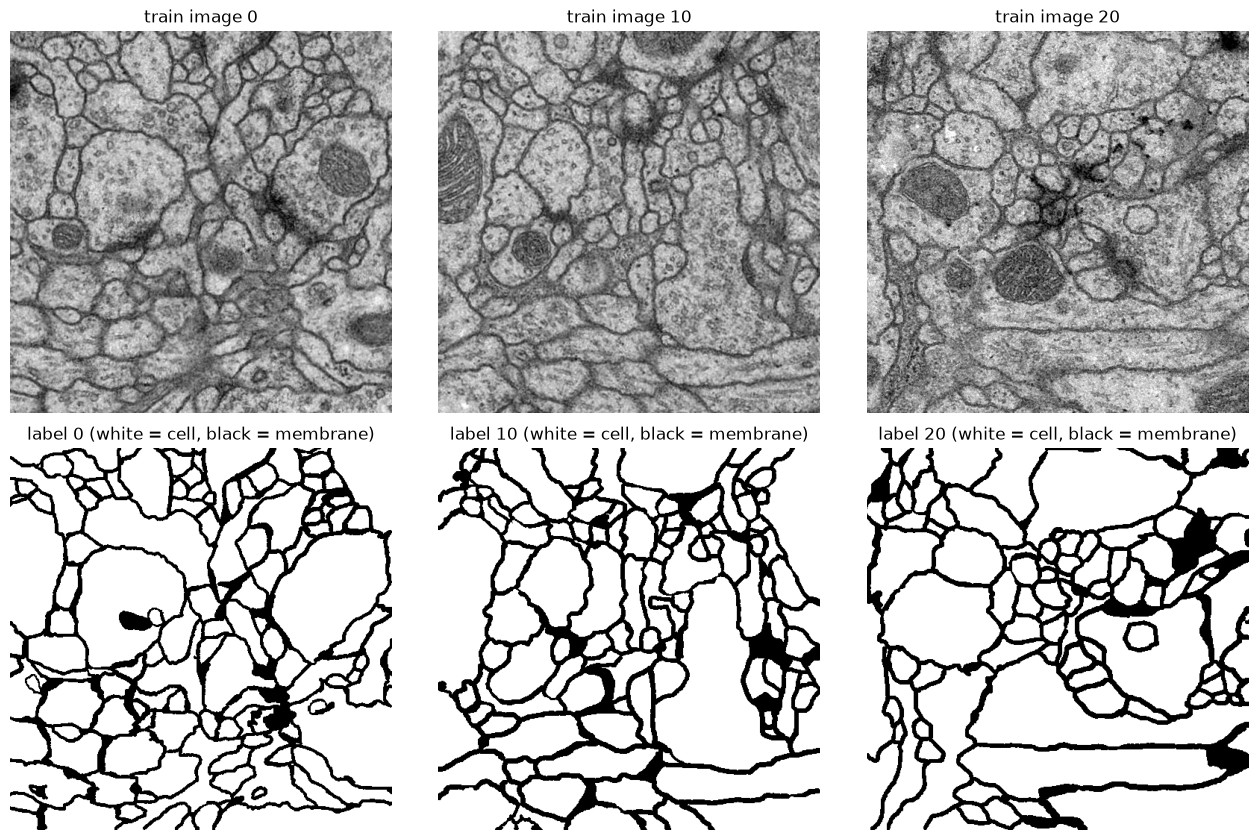

Membrane pixels: 22.0% of the training labels


In [3]:
data = T.load_isbi2012(DATA_DIR)
for name, array in data.items():
    print(f"{name:13s} shape {array.shape}  dtype {array.dtype}  values {array.min()}..{array.max()}")

fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
for col, i in enumerate([0, 10, 20]):
    ax[0, col].imshow(data["train_images"][i], cmap="gray")
    ax[0, col].set_title(f"train image {i}")
    ax[1, col].imshow(data["train_labels"][i], cmap="gray")
    ax[1, col].set_title(f"label {i} (white = cell, black = membrane)")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

membrane_fraction = (data["train_labels"] == T.MEMBRANE).mean()
print(f"Membrane pixels: {membrane_fraction:.1%} of the training labels")

## 4. Training and validation split

We hold back the last few training slices as a **validation set**. With `N_VALIDATION = 5`, slices 0 to 24 (25 images) are used for training and slices 25 to 29 (5 images) for validation. The model never trains on them. Every `EVAL_EVERY` iterations we check how well it does on them.

Why bother? A network with 31 million weights can simply *memorise* 30 images. That's called **overfitting**: the training loss keeps falling while results on new images get worse. Scoring on images the model hasn't seen tells us whether it is learning something general. We also use those scores to keep the **best checkpoint**, the saved copy of the weights from the point where validation scores were highest.

The **test set** is kept separate and only used once, at the very end. If we picked settings by looking at test scores, the test score would no longer be an honest estimate.

In [4]:
assert N_VALIDATION >= 1, "keep at least one validation slice"
train_images = pyunet.to_float(data["train_images"][:-N_VALIDATION])  # uint8 0..255 -> float 0..1
train_labels = data["train_labels"][:-N_VALIDATION]
val_images = data["train_images"][-N_VALIDATION:]
val_labels = data["train_labels"][-N_VALIDATION:]
print(f"{len(train_images)} training slices, {len(val_images)} validation slices, "
      f"{len(data['test_images'])} test slices")

25 training slices, 5 validation slices, 30 test slices


## 5. The weight map (paper Eq. 2, notes §7)

The loss adds up a penalty for every pixel. The weight map says how much each pixel's penalty counts:

$$w(x) = w_c(x) + w_0 \cdot \exp\left(-\frac{(d_1(x) + d_2(x))^2}{2\sigma^2}\right)$$

**Part 1, class balance $w_c$.** Only about 22% of pixels are membrane. A lazy network could label everything "cell" and still be 78% right. To stop that, $w_c$ makes each membrane pixel count about 2.3× and each cell pixel about 0.64×, so the two classes matter equally overall.

**Part 2, the border term.** $d_1$ and $d_2$ are the distances to the nearest and second-nearest cell. A membrane pixel squeezed between two cells has small $d_1 + d_2$, so it gets up to `W0` extra weight. Those thin gaps are what keep neighbouring cells apart: get a few of those pixels wrong and two cells merge into one, which is a big mistake even though only a handful of pixels are wrong. `SIGMA` controls how quickly the extra weight fades with distance. (We apply this term to membrane pixels only, which is what the paper's Fig. 3d shows.)

The map is computed once per label image, before training. That takes a second or two.

class weights: membrane 2.23, cell 0.64


weight maps for 25 slices in 0.9s; range 0.64 to 11.47


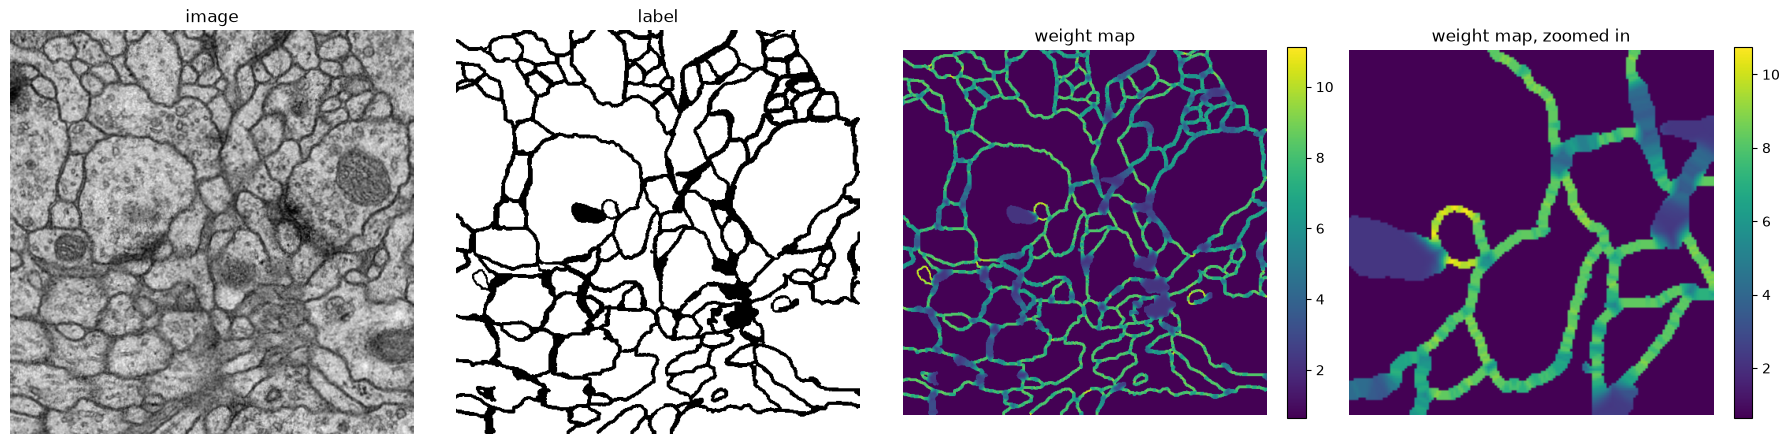

In [5]:
class_w = T.class_weights(train_labels)
print(f"class weights: membrane {class_w[T.MEMBRANE]:.2f}, cell {class_w[T.CELL]:.2f}")

t = time.time()
train_weights = T.weight_maps(train_labels, w0=W0, sigma=SIGMA, class_w=class_w)
print(f"weight maps for {len(train_weights)} slices in {time.time() - t:.1f}s; "
      f"range {train_weights.min():.2f} to {train_weights.max():.2f}")

i, zoom = 0, (slice(150, 300), slice(150, 300))
fig, ax = plt.subplots(1, 4, figsize=(18, 4.8))
ax[0].imshow(train_images[i], cmap="gray"); ax[0].set_title("image")
ax[1].imshow(train_labels[i], cmap="gray"); ax[1].set_title("label")
im = ax[2].imshow(train_weights[i], cmap="viridis"); ax[2].set_title("weight map")
fig.colorbar(im, ax=ax[2], fraction=0.046)
im = ax[3].imshow(train_weights[i][zoom], cmap="viridis"); ax[3].set_title("weight map, zoomed in")
fig.colorbar(im, ax=ax[3], fraction=0.046)
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

In the zoomed panel, the brightest pixels are on thin membranes running between two nearby cells. Wide patches of membrane, far from any cell, only get the class weight (about 2.2), and cell interiors get the smallest weight (about 0.64).

## 6. Data augmentation (paper section 3.1, notes §9)

25 training images is very little for 31 million weights. **Augmentation** makes new, realistic training examples on the fly, so the network almost never sees exactly the same picture twice. For each training tile, `TileSampler`:

1. **Picks a random slice and a random window.** The network takes a 572×572 input and predicts the central 388×388 region. The extra 92-pixel border on each side is context the valid convolutions use up (notes §5). Where the window goes past the image edge, the image is **mirrored**, exactly as at prediction time.
2. **Rotates the window by a random angle and sometimes flips it.** Cells look the same at any orientation, so the network should too.
3. **Applies an elastic deformation**, the paper's key trick. Random shifts (standard deviation `ELASTIC_SIGMA` pixels) are drawn on a coarse 3×3 grid and smoothly interpolated to every pixel. This bends the image like rubber, imitating how real tissue varies.
4. **Varies brightness and contrast** slightly.

The **same** warp is applied to the image, its label and its weight map, so they stay aligned. Labels use nearest-neighbour sampling, so they stay exactly 0 or 1.

How it's done: rather than moving pixels, we work out *where in the original image* each output pixel should be read from, then let `torch.nn.functional.grid_sample` read all those positions at once on the GPU. That's why augmentation costs almost nothing here.

Below, the top-left example is *not* augmented, for comparison. The red square marks the 388×388 region whose labels are used.

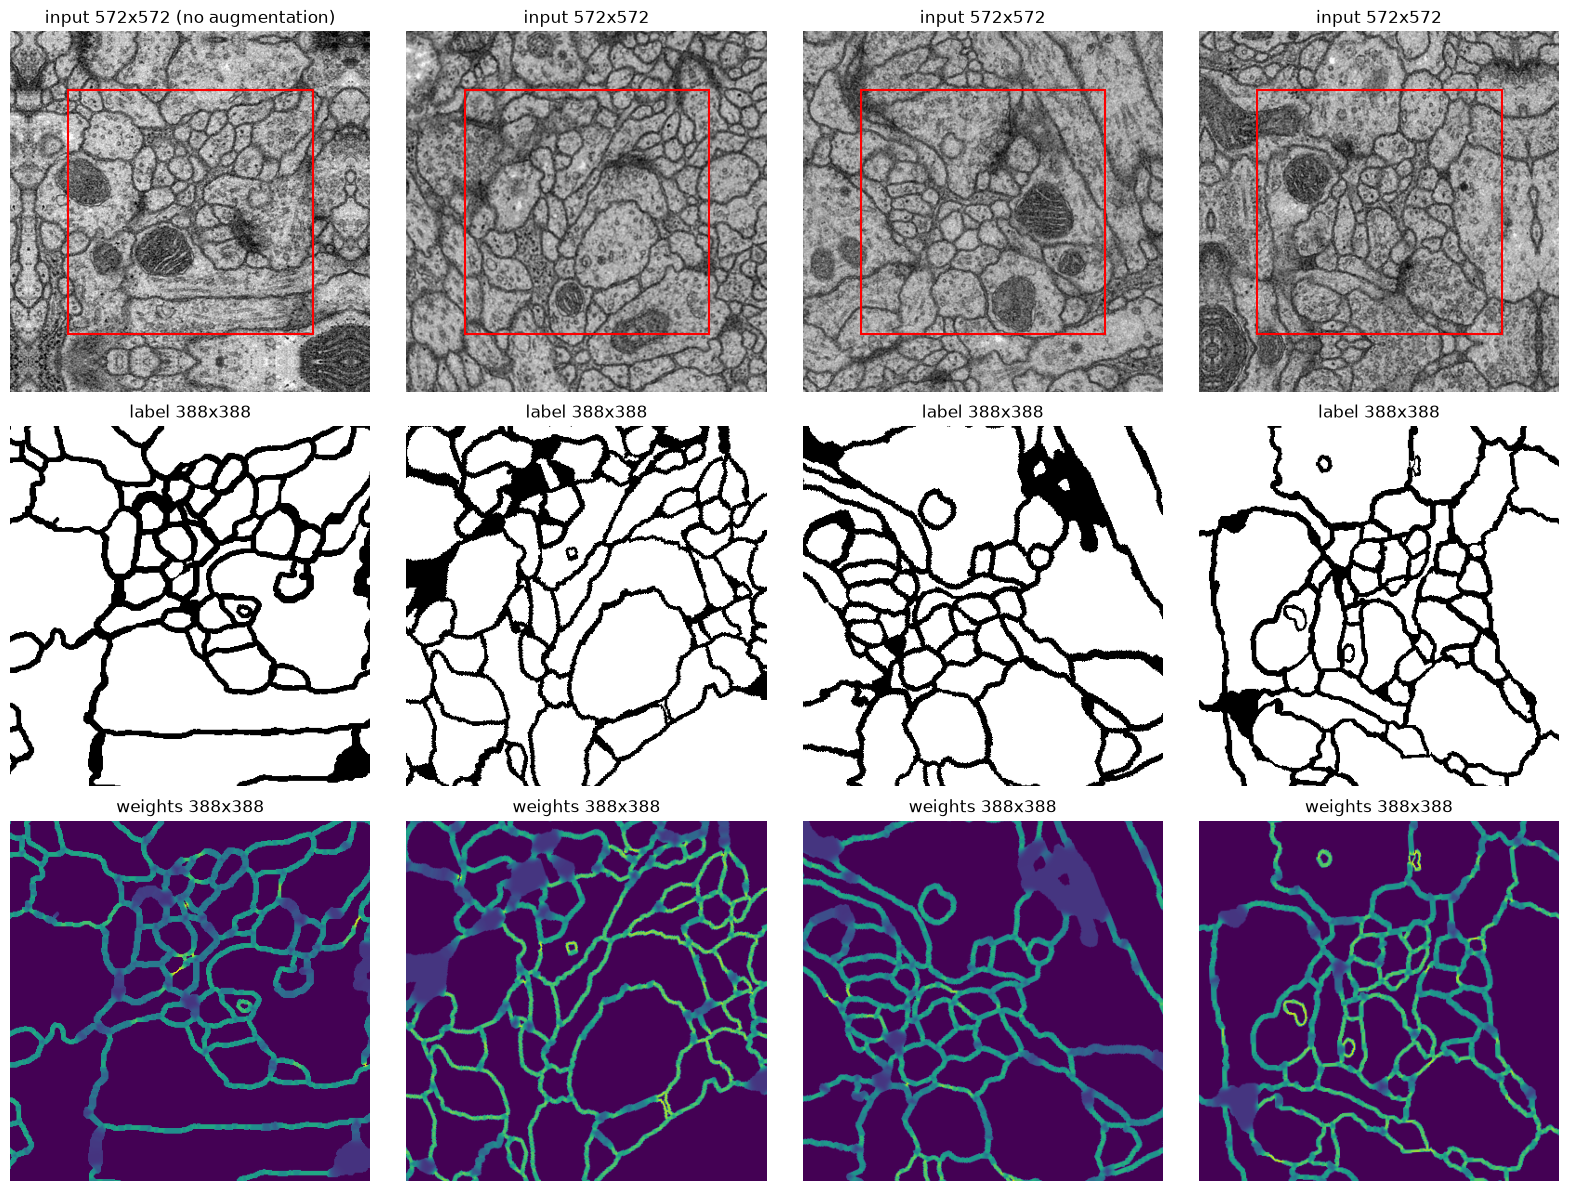

one batch: x (1, 1, 572, 572) | y (1, 388, 388) torch.int64 | w (1, 388, 388)


In [6]:
sampler = T.TileSampler(train_images, train_labels, train_weights, device,
                        elastic_sigma=ELASTIC_SIGMA, seed=SEED)

examples = [sampler.sample(1, augment=False)] + [sampler.sample(1) for _ in range(3)]
fig, ax = plt.subplots(3, 4, figsize=(16, 12))
for col, (x, y, w) in enumerate(examples):
    ax[0, col].imshow(x[0, 0].cpu(), cmap="gray")
    ax[0, col].add_patch(plt.Rectangle((92, 92), 388, 388, fill=False, color="red", lw=1.5))
    ax[0, col].set_title("input 572x572" + (" (no augmentation)" if col == 0 else ""))
    ax[1, col].imshow(y[0].cpu(), cmap="gray"); ax[1, col].set_title("label 388x388")
    ax[2, col].imshow(w[0].cpu(), cmap="viridis"); ax[2, col].set_title("weights 388x388")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()
print("one batch:", "x", tuple(x.shape), "| y", tuple(y.shape), y.dtype, "| w", tuple(w.shape))

## 7. The model (notes §3, §4, §8)

`pyunet.UNetPhseg` is the U-Net from the paper with valid (unpadded) convolutions, exactly as the authors released it. Its only difference from the paper's figure is that the last up-convolution keeps 128 channels.

**Starting weights.** The paper starts from random weights drawn from a Gaussian with standard deviation $\sqrt{2/N}$, where $N$ is the number of inputs feeding each neuron (*He initialisation*, notes §8). `init_weights` does exactly that. Starting everything at zero wouldn't work, because identical weights get identical updates forever.

Setting `START_FROM = "phseg_v5"` instead starts from the authors' trained cell-tracking weights. That's **transfer learning**: those filters already detect edges and blobs, so training usually gets going faster. Both datasets use class 1 = cell interior, so the two output channels line up.

**Train vs eval mode.** `model.train()` switches dropout on: during training, half the values after the two deepest blocks are randomly zeroed each step, which discourages memorising. `model.eval()` switches it off for prediction. The helper functions handle this for you.

The output has **2 numbers per pixel**, raw scores called *logits*, one per class. The softmax function turns them into probabilities that add up to 1 (notes §6).

In [7]:
model = pyunet.UNetPhseg().to(device)
if START_FROM == "scratch":
    pyunet.init_weights(model)
elif START_FROM == "phseg_v5":
    pyunet.load_caffe_weights(model, "u-net-release/phseg_v5.caffemodel")
else:
    raise ValueError(START_FROM)
model.train()

print(f"{sum(p.numel() for p in model.parameters()):,} learnable parameters, starting from {START_FROM!r}")
with torch.no_grad():
    logits = model(x)
print("input ", tuple(x.shape), "-> output", tuple(logits.shape), "(batch, class scores, height, width)")
print("scores for the top-left pixel:", logits[0, :, 0, 0].tolist())
print("as probabilities (membrane, cell):", torch.softmax(logits[0, :, 0, 0].float(), 0).tolist())

31,100,354 learnable parameters, starting from 'scratch'


input  (1, 1, 572, 572) -> output (1, 2, 388, 388) (batch, class scores, height, width)
scores for the top-left pixel: [2.463433027267456, -0.7706230282783508]
as probabilities (membrane, cell): [0.9620959758758545, 0.037904057651758194]


## 8. The loss (paper Eq. 1, notes §7)

For each pixel, **cross-entropy** looks at the probability the network gives to the *correct* class and takes $-\log$ of it. It's near 0 when the network is confident and right, and very large when it is confident and wrong. The weighted version multiplies each pixel's penalty by the weight map, then divides by the total weight. That gives a weighted average, which is also what the authors' Caffe code does:

$$\text{loss} = \frac{\sum_x w(x)\,\big(-\log p_{\text{true class}}(x)\big)}{\sum_x w(x)}$$

`F.cross_entropy` applies the softmax for us, which is why the model outputs raw scores. A network that guesses 50/50 everywhere would score $-\log 0.5 \approx 0.69$. An untrained network's guesses are arbitrary rather than 50/50, so its first loss is usually a bit higher, around 1. By the end of training it falls to about 0.2.

In [8]:
with torch.no_grad():
    print(f"loss on that tile before any training: {T.weighted_cross_entropy(logits.float(), y, w).item():.3f}")

loss on that tile before any training: 0.965


## 9. The optimiser and learning rate

The **optimiser** decides how to change the weights once the gradients are known.

- **SGD with momentum** is what the paper used (momentum 0.99, notes §8). Each update follows a running average of recent gradients, like a heavy ball rolling downhill. It works, but it's sensitive to the learning rate.
- **Adam** (the default here) also keeps a running average, but adapts the step size for every weight separately. It's much more forgiving, which is why it's the usual first choice today. In short test runs on this data, Adam at `1e-4` learned faster and more reliably than the paper's SGD settings.

The **learning rate** is the step size. Too big and training jumps around or blows up (the loss goes to `nan`); too small and it crawls.

**Mixed precision.** With `USE_MIXED_PRECISION`, `torch.autocast` runs the convolutions in 16-bit *bfloat16*. That has fewer digits of precision than float32 but the same range, so it's safe for training, and your GPU's tensor cores run it much faster. The loss and weight updates are still done in float32.

In [9]:
if OPTIMIZER == "adam":
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
elif OPTIMIZER == "sgd":
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.99)
else:
    raise ValueError(OPTIMIZER)

# Everything we record during training. Re-running the training cell appends to this.
history = {"loss": [], "eval_iteration": [], "pixel_error": [], "rand_score": []}
best_rand = -1.0
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


## 10. Measuring progress

Every `EVAL_EVERY` iterations we predict the whole validation slices, using the same overlap-tile method as the released code (`pyunet.predict`), and compute two scores:

- **Pixel error** is the fraction of pixels labelled wrongly when we call a pixel "cell" if P(cell) > 0.5. Lower is better. It's easy to understand, but it doesn't care *which* pixels are wrong.
- **Rand score** asks a different question. We split the prediction into separate cells (connected regions, grown to fill the membranes) and check, for pairs of pixels, whether the prediction groups them the same way the ground truth does. 1.0 is perfect. It punishes the errors that matter most: a tiny gap in a membrane merges two cells and costs a lot, while a slightly thick membrane costs little.

The challenge ranks entries by a version of the Rand score. Ours is close, but not identical: the official Fiji script also tries many thresholds and thins the membranes first. So treat our numbers as a guide rather than leaderboard values.

**Expect the two scores to disagree a little.** With the border weighting on (`W0 = 10`) the network deliberately draws membranes thicker than the hand-drawn labels, because missing a membrane costs far more than a thick one. That keeps the pixel error around 0.1, while the Rand score, the one that measures whether cells are separated correctly, ends up higher. In short test runs, `W0 = 10` reached a Rand score of about 0.98 after 2,000 iterations, against about 0.96 with `W0 = 0`.

Here is the untrained network, as a baseline:

In [10]:
_, metrics = T.evaluate(model, val_images, val_labels)
print(f"before training: pixel error {metrics['pixel_error']:.4f}, Rand score {metrics['rand_score']:.4f}")

before training: pixel error 0.7952, Rand score 0.0108


## 11. Train!

This is the training loop. Each pass through it is one training step, as described in the primer:

```python
x, y, w = sampler.sample(BATCH_SIZE)          # an augmented tile, its labels and weights
logits = model(x)                             # forward pass
loss = T.weighted_cross_entropy(logits, y, w) # how wrong was it?
optimizer.zero_grad()                         # clear the previous step's gradients
loss.backward()                               # compute the gradients
optimizer.step()                              # nudge every weight
```

(`zero_grad` is needed because PyTorch *adds* new gradients to old ones unless you clear them.)

Every `EVAL_EVERY` iterations the cell:
- scores the validation slices and redraws the plots
- saves a **checkpoint** to `checkpoints/isbi2012_best.pth` whenever the Rand score beats its previous best. A checkpoint is a file holding all the weights, so you can reload the model later without retraining.

**What to expect:** the loss falls quickly at first, then slowly. The Rand score passes 0.9 within the first thousand or so iterations, then bounces between about 0.9 and 0.98. It bounces because only 5 validation slices are scored, so a single merged pair of cells moves the average noticeably. That's why we keep the *best* checkpoint rather than just the last one. The loss curve is noisy because every tile is different; the dark line is a moving average.

Press ■ to stop early: the model keeps what it has learned so far, and the latest weights are saved to `checkpoints/isbi2012_last.pth`. Run the cell again to continue. If it has finished, raise `N_ITERATIONS` in section 2 first.

iteration 10000/10000  loss (last 100) 0.2038  val pixel error 0.1044  val Rand 0.9751
elapsed 11.1 min, about 0.0 min to go


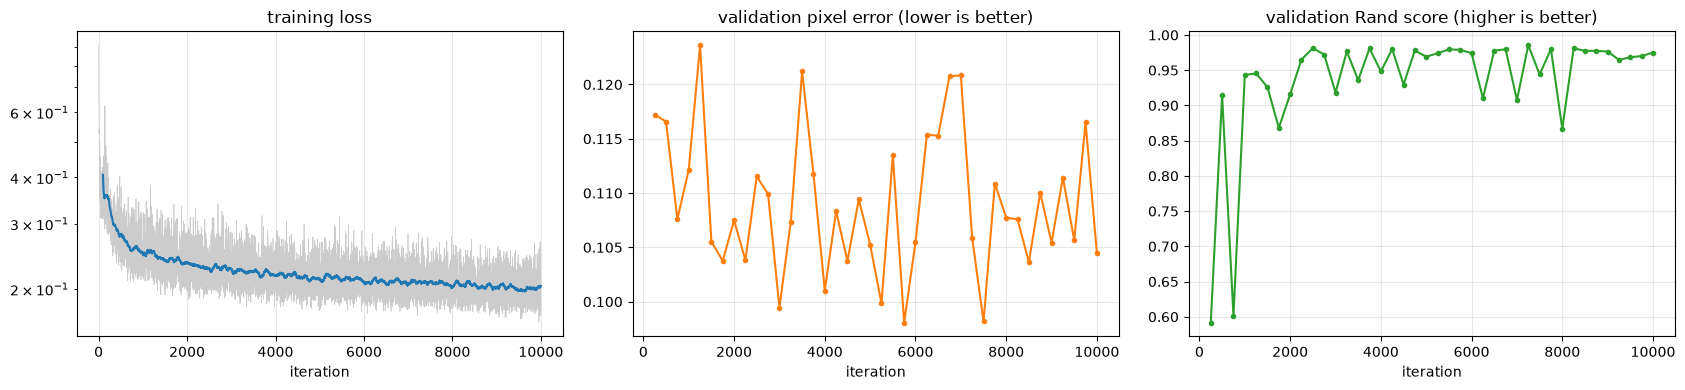

Best validation Rand score: 0.9855. Latest weights saved to checkpoints/isbi2012_last.pth


In [11]:
def plot_progress(history):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    loss = np.array(history["loss"])
    ax[0].plot(loss, color="0.8", lw=0.5)
    if len(loss) >= 100:
        ax[0].plot(np.arange(99, len(loss)), np.convolve(loss, np.ones(100) / 100, "valid"), color="C0")
    ax[0].set(title="training loss", xlabel="iteration", yscale="log")
    ax[1].plot(history["eval_iteration"], history["pixel_error"], "o-", color="C1", ms=3)
    ax[1].set(title="validation pixel error (lower is better)", xlabel="iteration")
    ax[2].plot(history["eval_iteration"], history["rand_score"], "o-", color="C2", ms=3)
    ax[2].set(title="validation Rand score (higher is better)", xlabel="iteration")
    for a in ax:
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def save_checkpoint(path, iteration, metrics):
    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "iteration": iteration,
        "metrics": metrics,
        "settings": {"start_from": START_FROM, "optimizer": OPTIMIZER, "lr": LEARNING_RATE,
                     "w0": W0, "sigma": SIGMA, "elastic_sigma": ELASTIC_SIGMA},
    }, path)


CHECKPOINT_DIR.mkdir(exist_ok=True)
model.train()
start = len(history["loss"])
t0 = time.time()
try:
    for it in range(start + 1, N_ITERATIONS + 1):
        x, y, w = sampler.sample(BATCH_SIZE)
        with torch.autocast(device, dtype=torch.bfloat16, enabled=USE_MIXED_PRECISION):
            logits = model(x)
        loss = T.weighted_cross_entropy(logits.float(), y, w)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history["loss"].append(loss.item())

        if it % EVAL_EVERY == 0 or it == N_ITERATIONS:
            _, metrics = T.evaluate(model, val_images, val_labels)
            history["eval_iteration"].append(it)
            history["pixel_error"].append(metrics["pixel_error"])
            history["rand_score"].append(metrics["rand_score"])
            note = ""
            if metrics["rand_score"] > best_rand:
                best_rand = metrics["rand_score"]
                save_checkpoint(CHECKPOINT_DIR / "isbi2012_best.pth", it, metrics)
                note = "  <- new best, saved"
            elapsed = time.time() - t0
            remaining = elapsed / (it - start) * (N_ITERATIONS - it)
            clear_output(wait=True)
            print(f"iteration {it}/{N_ITERATIONS}  loss (last 100) {np.mean(history['loss'][-100:]):.4f}  "
                  f"val pixel error {metrics['pixel_error']:.4f}  val Rand {metrics['rand_score']:.4f}{note}")
            print(f"elapsed {elapsed / 60:.1f} min, about {remaining / 60:.1f} min to go")
            plot_progress(history)
except KeyboardInterrupt:
    print(f"Stopped at iteration {len(history['loss'])}. Run this cell again to continue.")

save_checkpoint(CHECKPOINT_DIR / "isbi2012_last.pth", len(history["loss"]), None)
print(f"Best validation Rand score: {best_rand:.4f}. Latest weights saved to checkpoints/isbi2012_last.pth")

## 12. Load the best checkpoint and look at its predictions

The weights at the end of training aren't always the best ones, so we reload the checkpoint with the highest validation Rand score. `torch.load` reads the file, and `load_state_dict` copies the saved weights into the model.

For the final predictions we also switch on **flip averaging**: each image is predicted four times (as is, flipped left-right, flipped up-down, and both) and the scores are averaged. That's the same trick as the authors' released code, and it smooths out small mistakes.

The panels show the image, the true labels, the network's P(cell), and the predicted cells, each in its own colour. Two cells that share a colour patch have been merged; one cell split across several colours has been split.

loaded the best checkpoint from iteration 7250: {'pixel_error': 0.10585174560546876, 'rand_score': 0.985484167612842}


validation with flip averaging: pixel error 0.1036, Rand score 0.9812


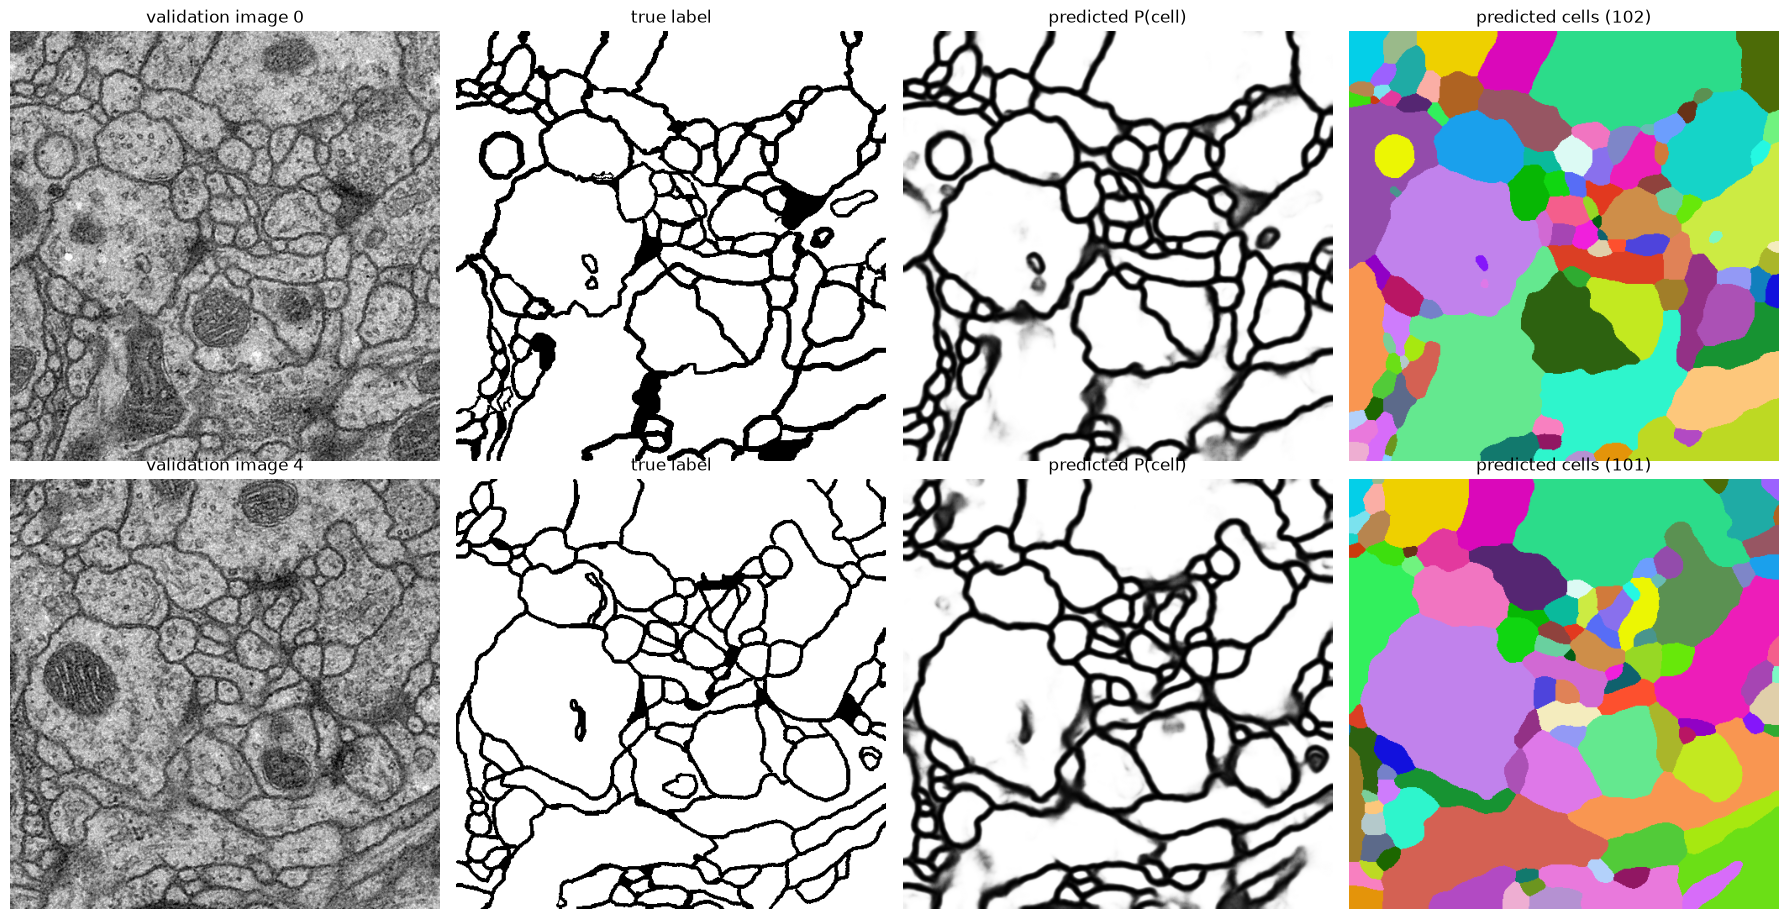

In [12]:
checkpoint = torch.load(CHECKPOINT_DIR / "isbi2012_best.pth", map_location=device)
model.load_state_dict(checkpoint["model"])
print(f"loaded the best checkpoint from iteration {checkpoint['iteration']}: {checkpoint['metrics']}")

val_probs, val_metrics = T.evaluate(model, val_images, val_labels, flip_average=True)
print(f"validation with flip averaging: pixel error {val_metrics['pixel_error']:.4f}, "
      f"Rand score {val_metrics['rand_score']:.4f}")


def show_predictions(images, labels, probs, indices, title):
    fig, ax = plt.subplots(len(indices), 4, figsize=(18, 4.6 * len(indices)), squeeze=False)
    for row, i in enumerate(indices):
        cells = T.segment(probs[i])
        rng = np.random.default_rng(0)
        colours = rng.random((cells.max() + 1, 3))
        ax[row, 0].imshow(images[i], cmap="gray"); ax[row, 0].set_title(f"{title} image {i}")
        ax[row, 1].imshow(labels[i], cmap="gray"); ax[row, 1].set_title("true label")
        ax[row, 2].imshow(probs[i], cmap="gray", vmin=0, vmax=1); ax[row, 2].set_title("predicted P(cell)")
        ax[row, 3].imshow(colours[cells]); ax[row, 3].set_title(f"predicted cells ({cells.max()})")
        for a in ax[row]:
            a.axis("off")
    plt.tight_layout()
    plt.show()


show_predictions(val_images, val_labels, val_probs, [0, N_VALIDATION - 1], "validation")

## 13. Final score on the test set

Now, once, the 30 test slices the model has never seen in any form.

For comparison, the paper's U-Net (trained much longer on all 30 slices, and scored by the official script) reached a pixel error of 0.0611 and a Rand error of 0.0382, roughly a Rand score of 0.96. As explained in section 10, our scores are computed slightly differently, so treat that as a ballpark rather than a like-for-like comparison.

The probability maps are saved to `outputs/isbi2012_test_probabilities.tif`, one 32-bit slice per test image with P(cell) between 0 and 1. That's the format the challenge accepted, and Fiji or ImageJ can open it.

test set (30 slices, 7s): pixel error 0.0847, Rand score 0.9763
saved outputs\isbi2012_test_probabilities.tif


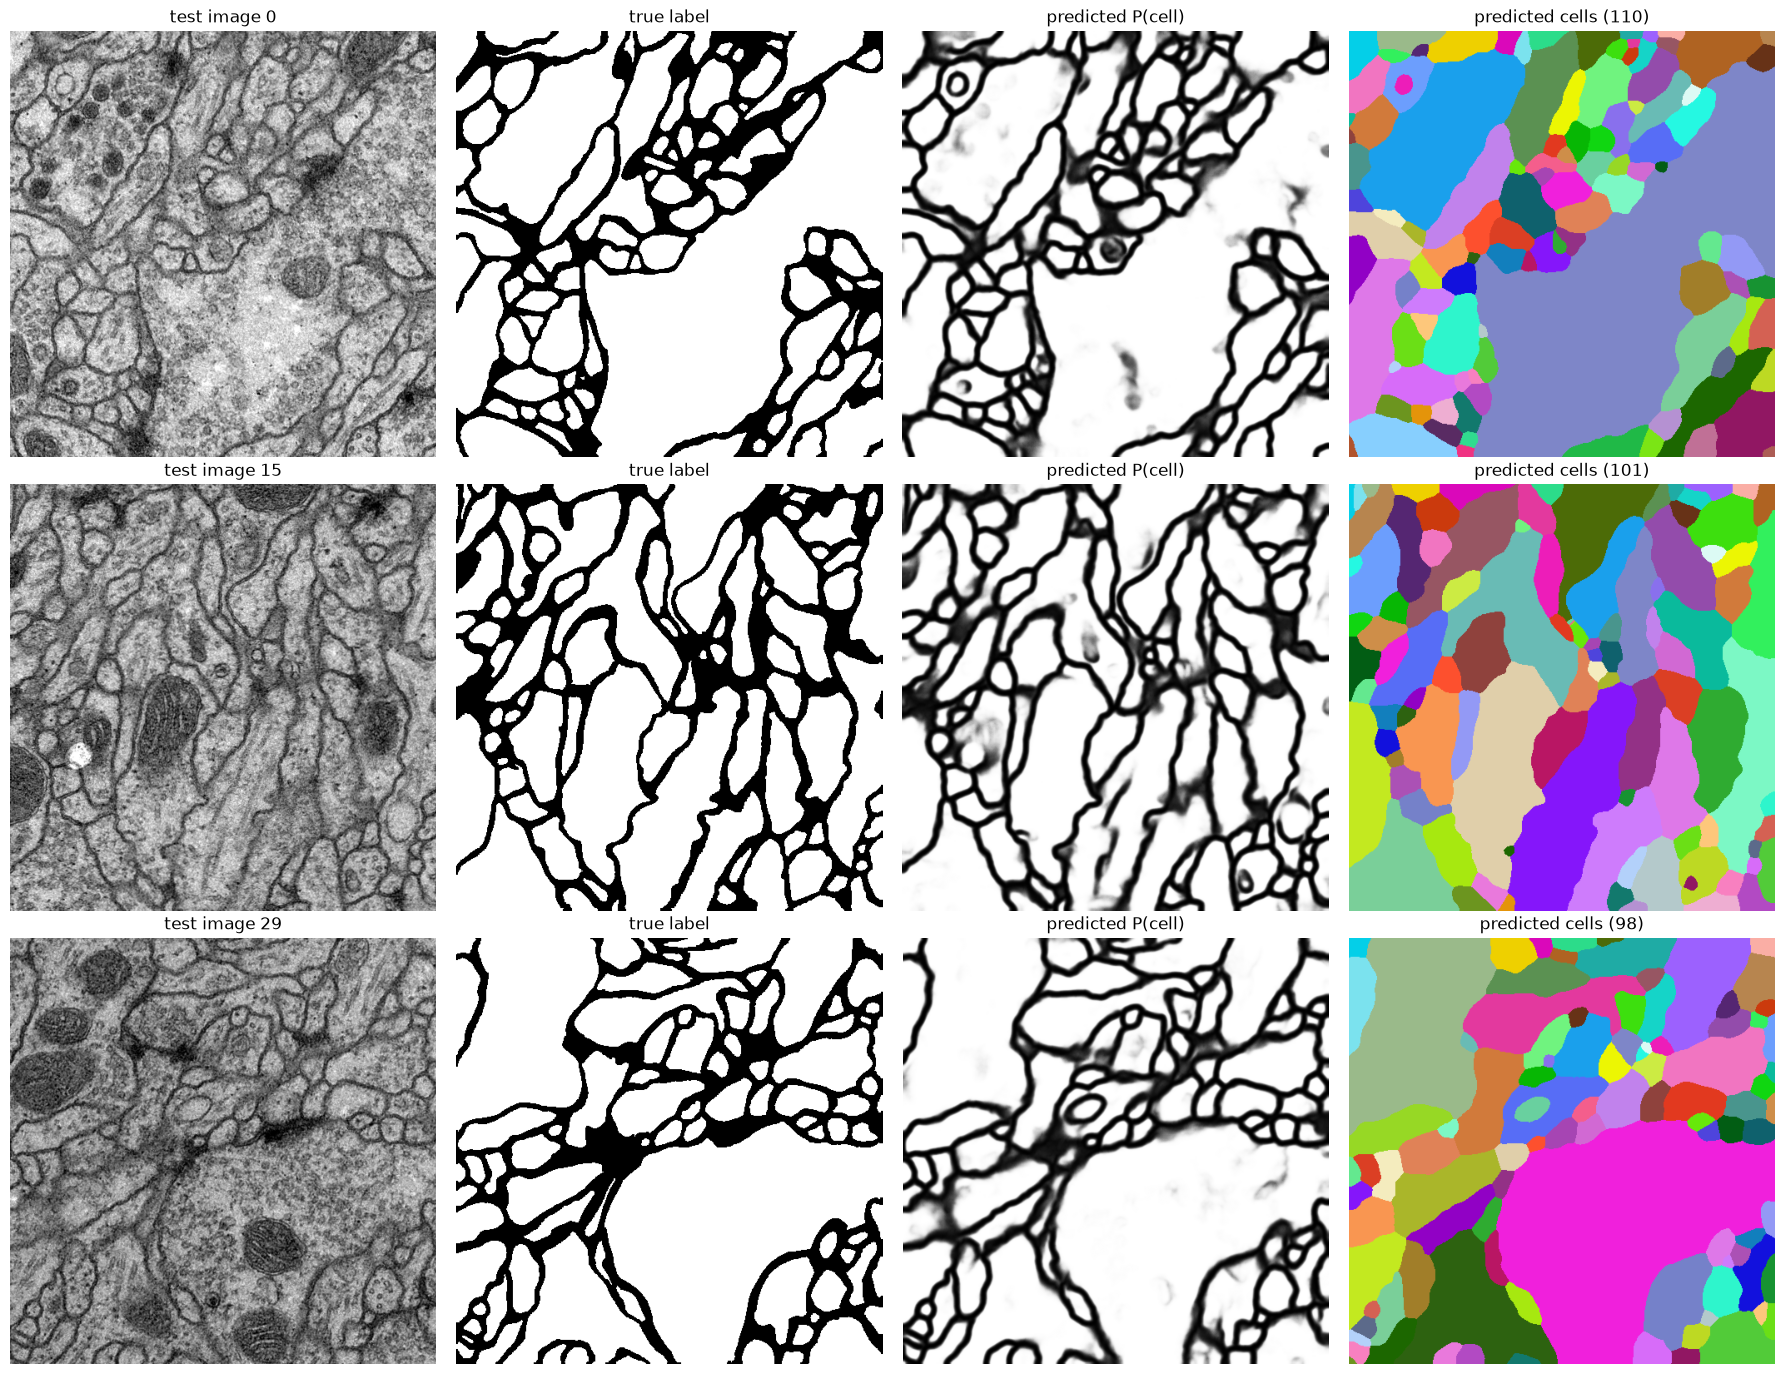

In [13]:
t = time.time()
test_probs, test_metrics = T.evaluate(model, data["test_images"], data["test_labels"], flip_average=True)
print(f"test set ({len(test_probs)} slices, {time.time() - t:.0f}s): "
      f"pixel error {test_metrics['pixel_error']:.4f}, Rand score {test_metrics['rand_score']:.4f}")

OUTPUT_DIR.mkdir(exist_ok=True)
tifffile.imwrite(OUTPUT_DIR / "isbi2012_test_probabilities.tif", test_probs.astype(np.float32))
print("saved", OUTPUT_DIR / "isbi2012_test_probabilities.tif")

show_predictions(data["test_images"], data["test_labels"], test_probs, [0, 15, 29], "test")

## 14. Things to try next

Change a setting in section 2, then **Run All** again. The checkpoints are overwritten, so rename them first if you want to keep a run.

- **Train longer**: `N_ITERATIONS = 30_000`. The paper trained for about 10 hours.
- **Turn the border weighting off**: `W0 = 0`. Compare the Rand score, and look at whether neighbouring cells merge more often.
- **Transfer learning**: `START_FROM = "phseg_v5"`. Does it get to a good score in fewer iterations?
- **The paper's optimiser**: `OPTIMIZER = "sgd"` with `LEARNING_RATE = 1e-3`.
- **Less augmentation**: `ELASTIC_SIGMA = 0`. Does the validation score drop, or does the training loss fall faster than the validation score improves? The second would be a sign of overfitting.
- **Thresholds**: everything above uses P(cell) > 0.5. Try `T.segment(prob, threshold=0.3)` or `0.7` on the test probabilities and see how the Rand score changes.